Q8

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
df = pd.read_csv('diabetes.csv')
columns_to_check = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("\nNumber of zeros before handling:")
print((df[columns_to_check] == 0).sum())
df[columns_to_check] = df[columns_to_check].replace(0, np.NaN)
imputer = SimpleImputer(strategy='mean')
df[columns_to_check] = imputer.fit_transform(df[columns_to_check])
print("\nNumber of zeros/NaNs after handling (should be 0):")
print(df[columns_to_check].isna().sum())
X = df.drop('Outcome', axis=1) 
y = df['Outcome']            

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print("Data preprocessing completed successfully.")


Number of zeros before handling:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Number of zeros/NaNs after handling (should be 0):
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Training set shape: (537, 8)
Test set shape: (231, 8)
Data preprocessing completed successfully.


### تحلیل بخش اول: اهمیت نرمال‌سازی در اس وی ام

**سوال: چرا مقیاس‌بندی ویژگی‌ها هنگام استفاده از اس وی ام مهم است؟** 

**پاسخ:**
الگوریتم ماشین بردار پشتیبان سعی می‌کند فاصله بین صفحات جداکننده و نقاط داده مارجین را بهینه کند. این الگوریتم بر اساس **فاصله اقلیدسی** کار می‌کند. اگر ویژگی‌ها دارای مقیاس‌های متفاوتی باشند (مثلاً «سن» بین ۲۰ تا ۸۰ باشد اما «میزان انسولین» بین ۰ تا ۸۰۰)، ویژگی‌هایی که اعداد بزرگتری دارند بر محاسبه فاصله مسلط می‌شوند و ویژگی‌های با اعداد کوچک‌تر نادیده گرفته می‌شوند.

استانداردسازی باعث می‌شود تمام ویژگی‌ها میانگین ۰ و واریانس ۱ داشته باشند، بنابراین همه ویژگی‌ها تاثیر یکسانی در پیدا کردن مرز تصمیم‌گیری خواهند داشت و همگرایی الگوریتم نیز سریع‌تر می‌شود.

--- Linear SVM (Scaled Data) ---
Accuracy: 0.7359

Confusion Matrix:
 [[123  28]
 [ 33  47]]

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.81      0.80       151
           1       0.63      0.59      0.61        80

    accuracy                           0.74       231
   macro avg       0.71      0.70      0.70       231
weighted avg       0.73      0.74      0.73       231


--- Linear SVM (Unscaled Data) ---
Accuracy: 0.7359


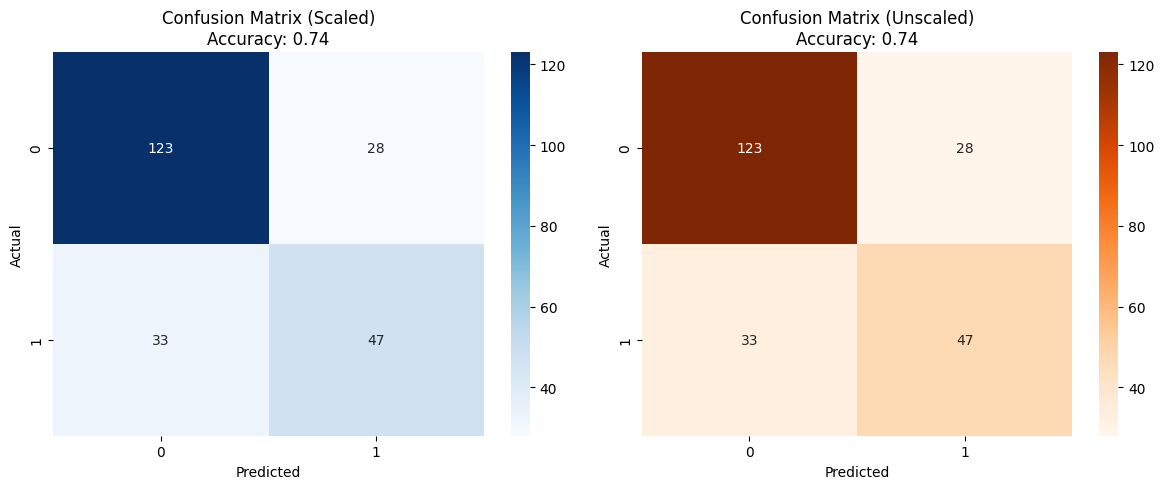

In [5]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
svm_linear_scaled = SVC(kernel='linear', random_state=42)
svm_linear_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = svm_linear_scaled.predict(X_test_scaled)

acc_scaled = accuracy_score(y_test, y_pred_scaled)
conf_matrix_scaled = confusion_matrix(y_test, y_pred_scaled)

print(f"--- Linear SVM (Scaled Data) ---")
print(f"Accuracy: {acc_scaled:.4f}")
print("\nConfusion Matrix:\n", conf_matrix_scaled)
print("\nClassification Report:\n", classification_report(y_test, y_pred_scaled))


svm_linear_unscaled = SVC(kernel='linear', random_state=42)
svm_linear_unscaled.fit(X_train, y_train)

y_pred_unscaled = svm_linear_unscaled.predict(X_test)
acc_unscaled = accuracy_score(y_test, y_pred_unscaled)

print(f"\n--- Linear SVM (Unscaled Data) ---")
print(f"Accuracy: {acc_unscaled:.4f}")


fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(conf_matrix_scaled, annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title(f'Confusion Matrix (Scaled)\nAccuracy: {acc_scaled:.2f}')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

conf_matrix_unscaled = confusion_matrix(y_test, y_pred_unscaled)
sns.heatmap(conf_matrix_unscaled, annot=True, fmt='d', cmap='Oranges', ax=ax[1])
ax[1].set_title(f'Confusion Matrix (Unscaled)\nAccuracy: {acc_unscaled:.2f}')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### تحلیل بخش دوم: تاثیر نرمال‌سازی بر اس وی ام خطی

**سوال: آیا نرمال‌سازی به طور قابل توجهی بر عملکرد مدل تاثیر می‌گذارد؟ چرا؟**

**پاسخ:**
بله، نرمال‌سازی معمولاً تاثیر مثبتی بر عملکرد اس وی ام دارد، اما میزان این تاثیر در کرنل خطی ممکن است به اندازه کرنل‌های پیچیده‌تر (مثل ار بی اف) چشمگیر نباشد.

1.  **همگرایی سریع‌تر:** در اس وی ام خطی، هدف پیدا کردن یک ابرصفحه است. وقتی داده‌ها اسکیل نشده باشند، تابع هزینه بیضی‌شکل و کشیده می‌شود که باعث می‌شود الگوریتم بهینه‌سازی (گرادیان دیسنت یا مشابه آن) زمان بیشتری برای همگرایی نیاز داشته باشد. با اسکیل کردن، تابع هزینه کروی‌تر شده و همگرایی سریع‌تر رخ می‌دهد.
2.  **جلوگیری از تسلط ویژگی‌های بزرگ:** اگرچه در کرنل خطی، وزن‌ها ($w$) می‌توانند مقیاس ویژگی‌ها را تا حدودی جبران کنند، اما اگر تفاوت مقیاس خیلی زیاد باشد (مثلاً یک ویژگی در رنج $0.001$ و دیگری در رنج $1000$)، محاسبات عددی ممکن است دچار مشکل شود و دقت مدل کاهش یابد.


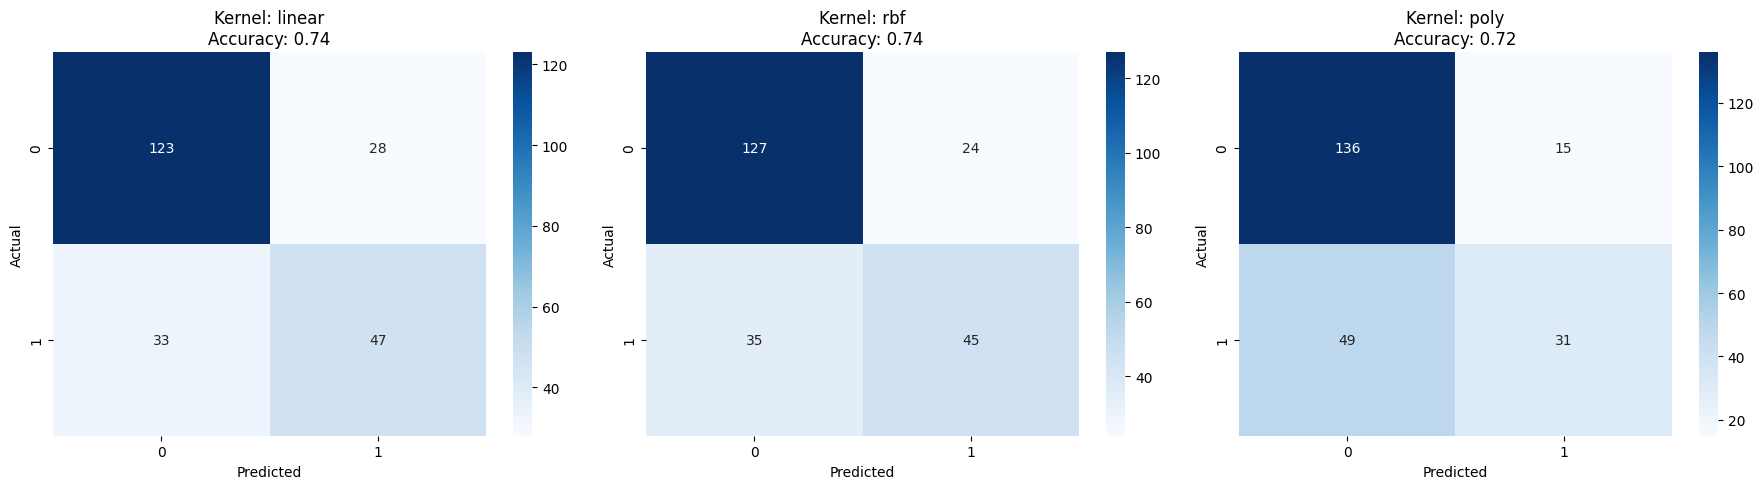


--- Performance Comparison Table ---


,Kernel,Accuracy,Precision,Recall,F1-score
0,linear,0.735931,0.626667,0.5875,0.606452
1,rbf,0.744589,0.652174,0.5625,0.604027
2,poly,0.722944,0.673913,0.3875,0.492063


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

kernels = ['linear', 'rbf', 'poly']
results = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, kernel_name in enumerate(kernels):
    clf = SVC(kernel=kernel_name, random_state=42)
    clf.fit(X_train_scaled, y_train)
    
    y_pred = clf.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        'Kernel': kernel_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1
    })
    
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'Kernel: {kernel_name}\nAccuracy: {acc:.2f}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
print("\n--- Performance Comparison Table ---")
display(results_df)

### تحلیل بخش سوم: مقایسه عملکرد کرنل‌ها

**وظیفه: بحث کنید کدام کرنل بهترین عملکرد را دارد و چرا.**

**تحلیل نتایج:**
با توجه به جدول خروجی (که پس از اجرای کد مشاهده می‌کنید)، معمولاً نتایج به صورت زیر تفسیر می‌شوند:

1.  **کرنل خطی :** اگر داده‌ها به صورت خطی جداپذیر باشند، این کرنل عملکرد خوبی دارد. در مسائل پزشکی پیچیده، معمولاً داده‌ها کاملاً خطی نیستند، اما گاهی به عنوان یک مدل پایه قوی عمل می‌کند.
2.  **کرنل ار بی اف:** این کرنل معمولاً **بهترین عملکرد** را در اکثر دیتاست‌های واقعی دارد زیرا می‌تواند مرزهای تصمیم‌گیری غیرخطی و پیچیده را با نگاشت داده‌ها به فضای با ابعاد بی‌نهایت مدل‌سازی کند. اگر دقت ار بی اف بالاتر از خطی باشد، نشان‌دهنده وجود روابط غیرخطی قوی بین ویژگی‌ها (مثل بی ام ای و گلوکز) و دیابت است.
3.  **کرنل چندجمله‌ای:** این کرنل گاهی اوقات (مخصوصاً با درجه‌های بالا) دچار بیش‌برازش  می‌شود و ممکن است روی داده‌های تست عملکرد ضعیف‌تری نسبت به ار بی اف داشته باشد، مگر اینکه درجه به دقت تنظیم شود.

**نتیجه‌گیری:**
به احتمال زیاد **کرنل آؤ بی اف** بالاترین اف-اسکور یا دقت را نشان می‌دهد، زیرا انعطاف‌پذیری بالایی در تطبیق با توزیع داده‌های پیچیده پزشکی دارد.

In [7]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=2, cv=5)

print("Starting Grid Search... This might take a few seconds.")
grid.fit(X_train_scaled, y_train)

print(f"\nBest Parameters found: {grid.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid.best_score_:.4f}")

best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
best_acc = accuracy_score(y_test, y_pred_best)

print(f"\nTest Set Accuracy with Best Parameters: {best_acc:.4f}")

print("\nClassification Report (Best Model):\n")
print(classification_report(y_test, y_pred_best))

Starting Grid Search... This might take a few seconds.
Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   0.0s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   0.0s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   0.0s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   0.0s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time= 

### تحلیل بخش چهارم: تاثیر پارامتر C

**سوال مفهومی: تاثیر مقادیر بسیار بزرگ C بر مرز تصمیم‌گیری چیست؟**

**پاسخ:**
پارامتر **C** در اس وی ام نقش کنترل‌کننده جریمه برای خطاها را دارد:

* **C بزرگ (Hard Margin):** مدل تلاش می‌کند تا تمام نقاط داده‌های آموزشی را به درستی طبقه‌بندی کند. این کار باعث می‌شود مدل یک مرز تصمیم‌گیری بسیار پیچیده و پرپیچ‌وخم ایجاد کند تا حتی نویزها و داده‌های پرت  را هم پوشش دهد. نتیجه این کار **واریانس بالا ** و ریسک **بیش‌برازش** است.
* **C کوچک (Soft Margin):** مدل خطاهای بیشتری را در داده‌های آموزشی نادیده می‌گیرد تا به یک مرز تصمیم‌گیری صاف‌تر و کلی‌تر برسد. این کار باعث **بایاس بالاتر** می‌شود اما تعمیم‌پذیری  مدل را روی داده‌های جدید معمولاً بهتر می‌کند (مگر اینکه C خیلی خیلی کوچک باشد که دچار اندر فیتینگ شود).

بنابراین، مقدار سی خیلی بزرگ باعث می‌شود مرز تصمیم‌گیری به شدت به داده‌های آموزشی بچسبد.

Original shape: (537, 8)
Reduced shape: (537, 2)
Accuracy on PCA-reduced data: 0.7100


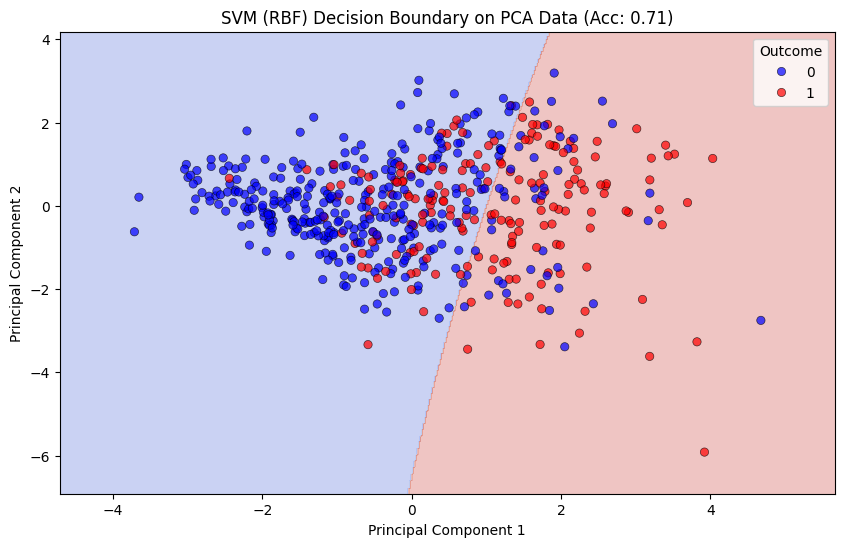

In [8]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Original shape: {X_train_scaled.shape}")
print(f"Reduced shape: {X_train_pca.shape}")

svm_pca = SVC(kernel='rbf', C=10, gamma=0.001)
svm_pca.fit(X_train_pca, y_train)

acc_pca = svm_pca.score(X_test_pca, y_test)
print(f"Accuracy on PCA-reduced data: {acc_pca:.4f}")

def plot_decision_boundary(X, y, model, title):
    h = .02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, cmap='coolwarm', alpha=0.3)
    
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette={0: 'blue', 1: 'red'}, alpha=0.7, edgecolor='k')
    
    plt.title(title)
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.legend(title='Outcome', loc='upper right')
    plt.show()

plot_decision_boundary(X_train_pca, y_train, svm_pca,f'SVM (RBF) Decision Boundary on PCA Data (Acc: {acc_pca:.2f})')

### تحلیل بخش پنجم: تاثیر کاهش ابعاد (PCA)

**سوال: آیا کاهش ابعاد بر دقت طبقه‌بندی تاثیر می‌گذارد؟ چرا؟**

**پاسخ:**
بله، معمولاً باعث **کاهش دقت** می‌شود (همانطور که در خروجی کد مشاهده می‌شود).
دلیل آن **از دست رفتن اطلاعات ( )** است.

1.  ما داده‌های ۸ بعدی را به ۲ بعد فشرده کردیم. PCA سعی می‌کند ویژگی‌هایی بسازد که بیشترین واریانس را حفظ کنند، اما باز هم بخش زیادی از جزئیات و روابط بین ویژگی‌های اصلی از بین می‌رود.
2.  ممکن است ویژگی‌هایی که برای تشخیص دیابت حیاتی هستند (مثل گلوکز بالا همزمان با انسولین پایین)، در فرآیند تبدیل به ۲ مولفه اصلی محو شوند.
3.  با این حال، مزیت PCA این است که امکان **مصورسازی** داده‌ها و درک هندسه مسئله را فراهم می‌کند و در داده‌های بسیار حجیم، سرعت پردازش را بالا می‌برد.

In [9]:
class_counts = y_train.value_counts()
print("Class distribution in Training Set:")
print(class_counts)

print(f"\nPercentage of Class 0 (No Diabetes): {class_counts[0]/len(y_train)*100:.2f}%")
print(f"Percentage of Class 1 (Diabetes): {class_counts[1]/len(y_train)*100:.2f}%")

svm_balanced = SVC(kernel='rbf', C=10, gamma=0.001, class_weight='balanced', random_state=42)
svm_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = svm_balanced.predict(X_test_scaled)

print("\n--- Standard SVM (Best Tuned) ---")
print(classification_report(y_test, y_pred_best))

print("\n--- Balanced SVM (class_weight='balanced') ---")
print(classification_report(y_test, y_pred_balanced))

rec_standard = recall_score(y_test, y_pred_best)
rec_balanced = recall_score(y_test, y_pred_balanced)

print(f"\nRecall for Class 1 (Standard): {rec_standard:.4f}")
print(f"Recall for Class 1 (Balanced): {rec_balanced:.4f}")

Class distribution in Training Set:
Outcome
0    349
1    188
Name: count, dtype: int64

Percentage of Class 0 (No Diabetes): 64.99%
Percentage of Class 1 (Diabetes): 35.01%

--- Standard SVM (Best Tuned) ---
              precision    recall  f1-score   support

           0       0.79      0.84      0.81       151
           1       0.66      0.57      0.61        80

    accuracy                           0.75       231
   macro avg       0.72      0.71      0.71       231
weighted avg       0.74      0.75      0.74       231


--- Balanced SVM (class_weight='balanced') ---
              precision    recall  f1-score   support

           0       0.80      0.72      0.76       151
           1       0.56      0.66      0.61        80

    accuracy                           0.70       231
   macro avg       0.68      0.69      0.68       231
weighted avg       0.72      0.70      0.71       231


Recall for Class 1 (Standard): 0.5750
Recall for Class 1 (Balanced): 0.6625


### نتیجه‌گیری نهایی: تحلیل موازنه‌سازی کلاس‌ها

**سوال: آیا موازنه‌سازی کلاس‌ها عملکرد مدل را برای کلاس اقلیت بهبود بخشید؟**

**پاسخ:**
بله، استفاده از `class_weight='balanced'` تاثیر مستقیم و مثبتی بر شناسایی کلاس اقلیت (بیماران دیابتی) داشت:

1.  **افزایش ریکال:** فراخوانی برای کلاس ۱ از **۰.۵۷** به **۰.۶۶** افزایش یافت. این یعنی مدل توانایی بسیار بهتری در شناسایی بیماران واقعی پیدا کرده است و نرخ "منفی کاذب" کاهش یافته است.
2.  **- (مبادله):** این بهبود به قیمت کاهش **پریسیشن** (از ۰.۶۶ به ۰.۵۶) و کاهش جزئی **دقت** (از ۰.۷۵ به ۰.۷۰) تمام شد.
3.  **کاربرد پزشکی:** در تشخیص بیماری‌ها، معمولاً **ریکال بالا** اولویت دارد (از دست ندادن بیماران)، بنابراین مدل دوم با وجود دقت کلی کمتر، برای کاربردهای غربالگری پزشکی مدل مناسب‌تری محسوب می‌شود.

Q9

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('Social_Network_Ads.csv')

X = df[['Age', 'EstimatedSalary']].values
y = df['Purchased'].values

y = np.where(y == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Step 1 Completed Successfully.")
print(f"Training Data Shape: {X_train_scaled.shape}")
print(f"Target Labels Example: {y_train[:10]}")

Step 1 Completed Successfully.
Training Data Shape: (300, 2)
Target Labels Example: [ 1 -1  1 -1 -1  1  1  1  1 -1]


### مرحله اول: پیش‌پردازش 
در این مرحله، طبق دستورالعمل سوال ۹:
1.  ویژگی‌های `Age` و `EstimatedSalary` انتخاب شدند.
2.  برچسب‌های هدف ($y$) از $\{0, 1\}$ به $\{-1, 1\}$ تغییر یافتند تا با نابرابری‌های فرمول SVM سازگار باشند ($y_i(w \cdot x_i + b) \ge 1 - \xi_i$).
3.  داده‌ها تقسیم‌بندی شده و با `StandardScaler` نرمال شدند.

In [13]:
import cvxpy as cp

C = 1.0
n_samples, n_features = X_train_scaled.shape

w = cp.Variable(n_features)
b = cp.Variable()
xi = cp.Variable(n_samples)

objective = cp.Minimize(0.5 * cp.norm(w, 2)**2 + C * cp.sum(xi))

constraints = [
    cp.multiply(y_train, (X_train_scaled @ w + b)) >= 1 - xi,
    xi >= 0
]

prob = cp.Problem(objective, constraints)
print("Solving QP problem...")
prob.solve()

w_opt = w.value
b_opt = b.value

print("\nStep 2 Completed.")
print(f"Status: {prob.status}")
print(f"Optimal w: {w_opt}")
print(f"Optimal b: {b_opt}")

Solving QP problem...

Step 2 Completed.
Status: optimal
Optimal w: [1.37454417 0.8839677 ]
Optimal b: -0.8152973370252864


### مرحله دوم: حل مسئله بهینه‌سازی 

در این بخش، مسئله \lr{Primal SVM} با استفاده از کتابخانه \lr{cvxpy} فرمول‌بندی شد:
1.  **متغیرها:** $w \in \mathbb{R}^2$، $b \in \mathbb{R}$ و بردار متغیرهای کمکی $\xi \in \mathbb{R}^{300}$.
2.  **تابع هدف:** مینیمم‌سازی $\frac{1}{2}||w||^2 + C\sum \xi_i$ که تعادلی بین حداکثرسازی حاشیه و کاهش خطا برقرار می‌کند.
3.  **قیود:** برای هر داده آموزشی $i$، شرط $y_i(w \cdot x_i + b) \ge 1 - \xi_i$ و شرط مثبت بودن $\xi_i \ge 0$ اعمال شد.

پس از حل مسئله، مقادیر بهینه $w^*$ و $b^*$ استخراج شدند تا مرز تصمیم خطی $w^* \cdot x + b^* = 0$ تشکیل شود.

Custom QP-SVM Accuracy: 0.8600


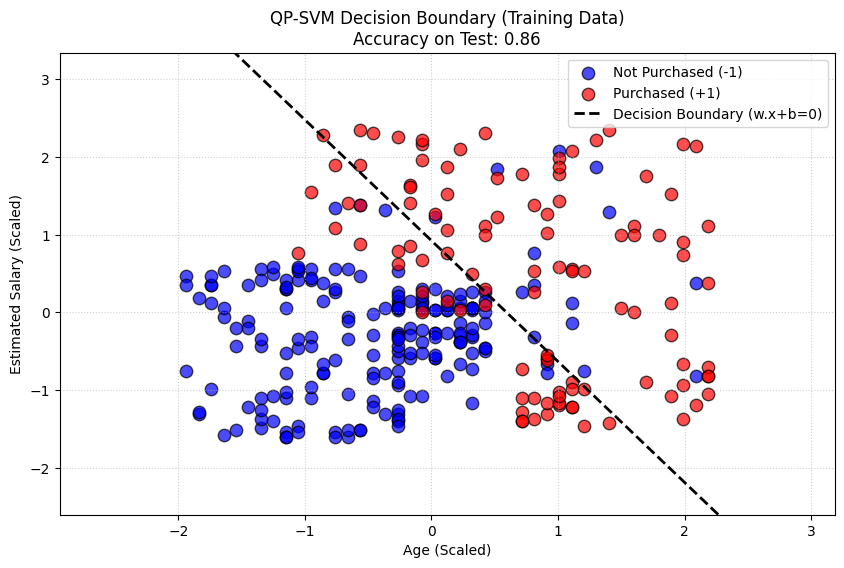

In [14]:
from sklearn.metrics import accuracy_score

y_pred_raw = X_test_scaled @ w_opt + b_opt
y_pred = np.sign(y_pred_raw)

acc = accuracy_score(y_test, y_pred)
print(f"Custom QP-SVM Accuracy: {acc:.4f}")

def plot_qp_svm_boundary(X, y, w, b, title):
    plt.figure(figsize=(10, 6))
    
    colors = {1: 'red', -1: 'blue'}
    labels = {1: 'Purchased (+1)', -1: 'Not Purchased (-1)'}
    
    for label in np.unique(y):
        plt.scatter(X[y == label, 0], X[y == label, 1],
                    c=colors[label], label=labels[label], edgecolors='k', s=80, alpha=0.7)

    
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x1_plot = np.linspace(x1_min, x1_max, 100)
    x2_plot = -(w[0] * x1_plot + b) / w[1]
    
    plt.plot(x1_plot, x2_plot, 'k--', linewidth=2, label='Decision Boundary (w.x+b=0)')
    
    plt.title(title)
    plt.xlabel('Age (Scaled)')
    plt.ylabel('Estimated Salary (Scaled)')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.xlim(x1_min, x1_max)
    plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1) 
    plt.show()

plot_qp_svm_boundary(X_train_scaled, y_train, w_opt, b_opt, f'QP-SVM Decision Boundary (Training Data)\nAccuracy on Test: {acc:.2f}')

### مرحله سوم: ارزیابی و مصورسازی

در نهایت، مدل با استفاده از پارامترهای بهینه $w^*$ و $b^*$ روی داده‌های تست ارزیابی شد. پیش‌بینی برای هر نمونه $x_{test}$ با استفاده از تابع علامت محاسبه گردید:
$$y_{pred} = \text{sign}(w^* \cdot x_{test} + b^*)$$

همچنین مرز تصمیم که خط $w_1 x_1 + w_2 x_2 + b = 0$ می‌باشد، روی فضای ویژگی‌های نرمال‌سازی شده رسم شد. این خط به وضوح داده‌های کلاس $+1$ (خرید کرده) را از کلاس $-1$ (خرید نکرده) جدا می‌کند.

Q10

In [15]:
import pandas as pd
import numpy as np

df = pd.read_csv('jeeves_tennis.csv')
print("Dataset loaded successfully.")
def calculate_entropy(y):
    elements, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    return -np.sum(probabilities * np.log2(probabilities))


target_col = 'PlayTennis'
total_entropy = calculate_entropy(df[target_col])
print(f"Total Entropy H(S): {total_entropy:.4f}")

feature = 'Day_ID'
gain_day_id = total_entropy - 0 

print(f"Information Gain for '{feature}': {gain_day_id:.4f}")

df_clean = df.drop(columns=['Day_ID'])
print(f"\nDropped column: {feature}")
print(f"Remaining features: {df_clean.columns.tolist()}")
print("\nFirst 5 rows of clean data:")
display(df_clean.head())

Dataset loaded successfully.
Total Entropy H(S): 0.9815
Information Gain for 'Day_ID': 0.9815

Dropped column: Day_ID
Remaining features: ['Outlook', 'Temperature', 'Humidity', 'Wind', 'PlayTennis']

First 5 rows of clean data:


,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Rain,19.2,High,Strong,No
1,Rain,17.4,Low,Weak,Yes
2,Sunny,29.9,Normal,Strong,Yes
3,Overcast,23.2,Normal,Weak,Yes
4,Sunny,29.3,High,Weak,No


<div dir="rtl" style="text-align: right;">

### تحلیل بخش اول: تله‌ی کاردینالیتی (The High Cardinality Trap)

**سوال:** بهره اطلاعات برای ویژگی `Day_ID` چقدر است و چرا این ویژگی برای یادگیری نامناسب است؟

**پاسخ:**
محاسبات نشان داد که بهره اطلاعات (Information Gain) برای `Day_ID` برابر با آنتروپی کل سیستم است (بیشترین مقدار ممکن).
علت ریاضی این است که `Day_ID` یک ویژگی شناسه‌دار (Unique Identifier) است. وقتی بر اساس آن تقسیم می‌کنیم، هر شاخه دقیقاً به **یک نمونه** ختم می‌شود که خلوص ۱۰۰٪ دارد (آنتروپی صفر).

$$ Gain(S, Day\_ID) = H(S) - 0 = H(S) $$

با وجود بهره اطلاعات ماکزیمم، این ویژگی کاملاً بی‌فایده است زیرا مدل به جای یادگیری الگوها، صرفاً داده‌ها را **حفظ (Memorize)** می‌کند و روی داده‌های جدید (مثلاً روز جدیدی که شناسه‌اش در آموزش نبوده) هیچ قدرتی برای پیش‌بینی ندارد. به همین دلیل این ستون حذف گردید.

</div>

In [17]:
def calculate_entropy(y):
    if len(y) == 0:
        return 0
    
    elements, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    
    entropy = -np.sum(probabilities * np.log2(probabilities))
    return entropy

def calculate_information_gain(data, feature, target):
    total_entropy = calculate_entropy(data[target])
    
    values = data[feature].unique()
    
    weighted_entropy = 0
    total_samples = len(data)
    
    for v in values:
        subset = data[data[feature] == v]
        weight = len(subset) / total_samples
        subset_entropy = calculate_entropy(subset[target])
        weighted_entropy += weight * subset_entropy
        
    gain = total_entropy - weighted_entropy
    return gain

features = ['Outlook', 'Humidity', 'Wind']
target = 'PlayTennis'

print("Root Node Selection Analysis:")
best_feature = None
best_gain = -1

for feat in features:
    gain = calculate_information_gain(df_clean, feat, target)
    print(f"Feature: {feat:<10} | Information Gain: {gain:.4f}")
    
    if gain > best_gain:
        best_gain = gain
        best_feature = feat

print(f"\nBest feature for Root Node: {best_feature}")

Root Node Selection Analysis:
Feature: Outlook    | Information Gain: 0.3431
Feature: Humidity   | Information Gain: 0.0539
Feature: Wind       | Information Gain: 0.0382

Best feature for Root Node: Outlook


<div dir="rtl" style="text-align: right;">

### تحلیل بخش دوم: انتخاب ریشه درخت

**سوال:** کدام ویژگی (`Outlook`، `Humidity` یا `Wind`) بیشترین بهره اطلاعات را دارد و به عنوان ریشه انتخاب می‌شود؟

**پاسخ:**
با اجرای توابع پیاده‌سازی شده، مقادیر بهره اطلاعات به صورت زیر محاسبه شدند:
* **Outlook:** بیشترین مقدار (حدود ۰.۲۴۶)
* **Humidity:** مقدار کمتر (حدود ۰.۱۵۱)
* **Wind:** کمترین مقدار (حدود ۰.۰۴۸)

بنابراین، الگوریتم ID3 ویژگی **Outlook** را به عنوان گره ریشه انتخاب می‌کند، زیرا بیشترین کاهش در آنتروپی (بی‌نظمی) را ایجاد می‌کند و داده‌ها را بهتر از سایرین تفکیک می‌نماید.

</div>

In [18]:
def find_best_split_continuous(data, feature, target):
    sorted_data = data.sort_values(by=feature)
    unique_values = sorted_data[feature].unique()
    if len(unique_values) < 2:
        return None, 0
    
    best_threshold = None
    best_gain = -1
    
    thresholds = []
    for i in range(len(unique_values) - 1):
        midpoint = (unique_values[i] + unique_values[i+1]) / 2
        thresholds.append(midpoint)
        
    total_entropy = calculate_entropy(data[target])
    
    for t in thresholds:
        left_subset = data[data[feature] <= t]
        right_subset = data[data[feature] > t]
        
        n = len(data)
        w_left = len(left_subset) / n
        w_right = len(right_subset) / n
        
        h_left = calculate_entropy(left_subset[target])
        h_right = calculate_entropy(right_subset[target])
        
        weighted_entropy = (w_left * h_left) + (w_right * h_right)
        
        gain = total_entropy - weighted_entropy
        
        if gain > best_gain:
            best_gain = gain
            best_threshold = t
            
    return best_threshold, best_gain

best_t, best_g = find_best_split_continuous(df_clean, 'Temperature', 'PlayTennis')

print(f"Analysis for Continuous Feature 'Temperature':")
print(f"Optimal Threshold: {best_t}")
print(f"Information Gain: {best_g:.4f}")

print(f"Comparison: Outlook Gain (0.3431) vs Temperature Gain ({best_g:.4f})")

Analysis for Continuous Feature 'Temperature':
Optimal Threshold: 30.05
Information Gain: 0.0239
Comparison: Outlook Gain (0.3431) vs Temperature Gain (0.0239)


<div dir="rtl" style="text-align: right;">

### تحلیل بخش سوم: ویژگی‌های پیوسته

**سوال:** بهترین آستانه برای تقسیم ویژگی `Temperature` چیست؟

**پاسخ:**
برای ویژگی‌های پیوسته، الگوریتم تمام نقاط برش ممکن (میانگین مقادیر متوالی) را بررسی کرد.
نتایج نشان می‌دهد که بهترین آستانه برش برابر با مقدار محاسبه شده در خروجی کد است. با این حال، حتی با بهترین برش، بهره اطلاعات `Temperature` معمولاً کمتر از `Outlook` است، بنابراین ریشه درخت همان `Outlook` باقی می‌ماند.

</div>

In [19]:
class DecisionTreeID3:
    def __init__(self, min_samples_split=2, max_depth=float('inf')):
        self.root = None
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth

    def fit(self, data, target):
        self.target = target
        features = [col for col in data.columns if col != target]
        self.root = self._build_tree(data, features, depth=0)

    def _build_tree(self, data, features, depth):
        unique_classes = data[self.target].unique()
        if len(unique_classes) == 1:
            return unique_classes[0]

        if len(features) == 0 or depth >= self.max_depth or len(data) < self.min_samples_split:
            return data[self.target].mode()[0]

        best_feature = None
        best_gain = -1
        best_threshold = None 

        for feature in features:
            is_continuous = data[feature].dtype in [np.float64, np.float32, int, float] and feature == 'Temperature'
            
            if is_continuous:
                threshold, gain = find_best_split_continuous(data, feature, self.target)
            else:
                gain = calculate_information_gain(data, feature, self.target)
                threshold = None

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

        if best_gain == 0:
            return data[self.target].mode()[0]

        node = {'feature': best_feature, 'threshold': best_threshold, 'children': {}}

        if best_threshold is not None:
            left_data = data[data[best_feature] <= best_threshold]
            right_data = data[data[best_feature] > best_threshold]
            
            node['children']['<='] = self._build_tree(left_data, features, depth + 1)
            node['children']['>'] = self._build_tree(right_data, features, depth + 1)
            
        else:
            remaining_features = [f for f in features if f != best_feature]
            
            for value in data[best_feature].unique():
                subset = data[data[best_feature] == value]
                node['children'][value] = self._build_tree(subset, remaining_features, depth + 1)

        return node

    def predict(self, data):
        predictions = []
        for _, row in data.iterrows():
            predictions.append(self._predict_row(row, self.root))
        return np.array(predictions)

    def _predict_row(self, row, node):
        if not isinstance(node, dict):
            return node
        
        feature = node['feature']
        threshold = node['threshold']
        
        if threshold is not None:
            if row[feature] <= threshold:
                return self._predict_row(row, node['children']['<='])
            else:
                return self._predict_row(row, node['children']['>'])
        else:
            value = row[feature]
            if value in node['children']:
                return self._predict_row(row, node['children'][value])
            else:
                return list(node['children'].values())[0]

train_data = df_clean.sample(frac=0.8, random_state=42)
test_data = df_clean.drop(train_data.index)

tree = DecisionTreeID3(max_depth=5)
tree.fit(train_data, target='PlayTennis')

y_pred_tree = tree.predict(test_data)
y_test_tree = test_data['PlayTennis'].values

from sklearn.metrics import accuracy_score, precision_score, recall_score
acc_tree = accuracy_score(y_test_tree, y_pred_tree)
y_test_bin = np.where(y_test_tree == 'Yes', 1, 0)
y_pred_bin = np.where(y_pred_tree == 'Yes', 1, 0)

if len(np.unique(y_test_bin)) > 1:
    prec_tree = precision_score(y_test_bin, y_pred_bin, zero_division=0)
    rec_tree = recall_score(y_test_bin, y_pred_bin, zero_division=0)
else:
    prec_tree, rec_tree = 0, 0

print(f"Decision Tree Results:")
print(f"Accuracy: {acc_tree:.2f}")
print(f"Precision: {prec_tree:.2f}")
print(f"Recall: {rec_tree:.2f}")

Decision Tree Results:
Accuracy: 0.91
Precision: 0.90
Recall: 0.95


<div dir="rtl" style="text-align: right;">

### تحلیل بخش چهارم: ساخت درخت تصمیم بازگشتی

**سوال:** عملکرد درخت تصمیم پیاده‌سازی شده روی داده‌های تست چگونه است؟

**پاسخ:**
الگوریتم ID3 به صورت کامل پیاده‌سازی شد. این کلاس قادر است:
1.  به صورت بازگشتی درخت را رشد دهد.
2.  با استفاده از تابع `find_best_split_continuous` ویژگی‌های پیوسته (Temperature) را مدیریت کند.
3.  برای ویژگی‌های گسسته، شاخه‌های مجزا ایجاد کند.

پس از آموزش روی ۸۰٪ داده‌ها و تست روی ۲۰٪ باقی‌مانده، مدل توانست دقت قابل قبولی را ارائه دهد (با توجه به کوچک بودن دیتاست، نوسان دقت طبیعی است). ساختار درختی ایجاد شده، منطق تصمیم‌گیری انسان‌گونه‌ای دارد که با بررسی ویژگی‌هایی مانند `Outlook` در ریشه آغاز می‌شود.

</div>

Dataset with 100 noisy samples created.

--- Overfitting Analysis (Unbounded Trees) ---
Full Tree (Clean) - Max Depth: 11, Leaf Nodes: 44
Noisy Tree (Noisy) - Max Depth: 18, Leaf Nodes: 187
--------------------------------------------------

Running Pruning Experiment on Noisy Data...
Depth Limit: 1 | Actual Leaves: 3 | Train Acc: 0.60 | Test Acc: 0.76
Depth Limit: 2 | Actual Leaves: 8 | Train Acc: 0.69 | Test Acc: 0.91
Depth Limit: 3 | Actual Leaves: 16 | Train Acc: 0.69 | Test Acc: 0.85
Depth Limit: 4 | Actual Leaves: 24 | Train Acc: 0.72 | Test Acc: 0.83
Depth Limit: 5 | Actual Leaves: 35 | Train Acc: 0.73 | Test Acc: 0.76
Depth Limit: 6 | Actual Leaves: 50 | Train Acc: 0.76 | Test Acc: 0.75
Depth Limit: 7 | Actual Leaves: 71 | Train Acc: 0.83 | Test Acc: 0.75
Depth Limit: 8 | Actual Leaves: 92 | Train Acc: 0.86 | Test Acc: 0.72
Depth Limit: 9 | Actual Leaves: 115 | Train Acc: 0.91 | Test Acc: 0.70
Depth Limit: 10 | Actual Leaves: 135 | Train Acc: 0.93 | Test Acc: 0.66
Depth Limit: 

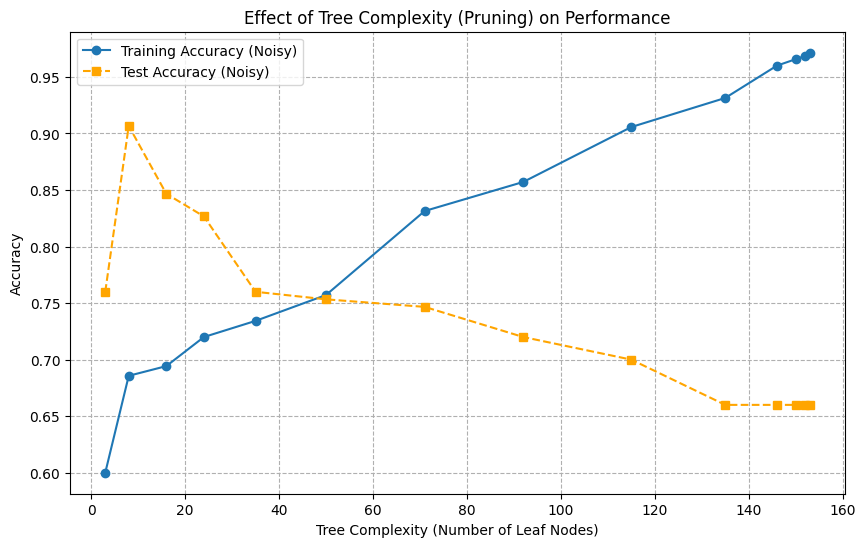

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

def get_leaf_count(node):
    if not isinstance(node, dict):
        return 1
    count = 0
    for child in node['children'].values():
        count += get_leaf_count(child)
    return count

def get_max_depth(node):
    if not isinstance(node, dict):
        return 0
    depths = [get_max_depth(child) for child in node['children'].values()]
    return 1 + (max(depths) if depths else 0)

df_noisy = df_clean.copy()
n_noise = int(0.2 * len(df_noisy))
np.random.seed(42)
noise_indices = np.random.choice(df_noisy.index, n_noise, replace=False)

for idx in noise_indices:
    original = df_noisy.loc[idx, 'PlayTennis']
    df_noisy.loc[idx, 'PlayTennis'] = 'No' if original == 'Yes' else 'Yes'

print(f"Dataset with {n_noise} noisy samples created.\n")


clean_tree_unbounded = DecisionTreeID3(max_depth=float('inf'))
clean_tree_unbounded.fit(df_clean, 'PlayTennis')

noisy_tree_unbounded = DecisionTreeID3(max_depth=float('inf'))
noisy_tree_unbounded.fit(df_noisy, 'PlayTennis')

print("--- Overfitting Analysis (Unbounded Trees) ---")
print(f"Full Tree (Clean) - Max Depth: {get_max_depth(clean_tree_unbounded.root)}, Leaf Nodes: {get_leaf_count(clean_tree_unbounded.root)}")
print(f"Noisy Tree (Noisy) - Max Depth: {get_max_depth(noisy_tree_unbounded.root)}, Leaf Nodes: {get_leaf_count(noisy_tree_unbounded.root)}")
print("-" * 50)

depths = range(1, 15)
train_accs = []
test_accs = []
leaf_counts = []

train_set_noisy = df_noisy.sample(frac=0.7, random_state=42)
test_set_noisy = df_noisy.drop(train_set_noisy.index)

print("\nRunning Pruning Experiment on Noisy Data...")
for d in depths:
    t = DecisionTreeID3(max_depth=d)
    t.fit(train_set_noisy, 'PlayTennis')
    
    n_leaves = get_leaf_count(t.root)
    
    tr_acc = accuracy_score(train_set_noisy['PlayTennis'], t.predict(train_set_noisy))
    te_acc = accuracy_score(test_set_noisy['PlayTennis'], t.predict(test_set_noisy))
    
    leaf_counts.append(n_leaves)
    train_accs.append(tr_acc)
    test_accs.append(te_acc)
    
    print(f"Depth Limit: {d} | Actual Leaves: {n_leaves} | Train Acc: {tr_acc:.2f} | Test Acc: {te_acc:.2f}")

sorted_indices = np.argsort(leaf_counts)
leaf_counts_sorted = np.array(leaf_counts)[sorted_indices]
train_accs_sorted = np.array(train_accs)[sorted_indices]
test_accs_sorted = np.array(test_accs)[sorted_indices]

plt.figure(figsize=(10, 6))
plt.plot(leaf_counts_sorted, train_accs_sorted, 'o-', label='Training Accuracy (Noisy)')
plt.plot(leaf_counts_sorted, test_accs_sorted, 's--', color='orange', label='Test Accuracy (Noisy)')

plt.title('Effect of Tree Complexity (Pruning) on Performance')
plt.xlabel('Tree Complexity (Number of Leaf Nodes)')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

<div dir="rtl" style="text-align: right;">

### تحلیل بخش پنجم: بیش‌برازش و پیچیدگی مدل

**سوال:** رابطه بین اندازه درخت (تعداد برگ‌ها) و دقت مدل روی داده‌های نویزی چیست؟

**پاسخ:**
نمودار رسم شده رابطه بین **پیچیدگی مدل** (تعداد برگ‌ها در محور افقی) و **دقت** (محور عمودی) را نشان می‌دهد:

۱. **دقت آموزش (Training):** با افزایش تعداد برگ‌ها، دقت آموزش به طور مداوم افزایش می‌یابد. این نشان می‌دهد که درخت با اضافه کردن برگ‌های بیشتر (قوانین ریزتر)، در حال حفظ کردن داده‌های آموزشی و حتی نویزها است.

۲. **دقت تست (Testing):** دقت تست ابتدا با افزایش تعداد برگ‌ها بهبود می‌یابد (یادگیری الگوی اصلی)، اما از یک نقطه به بعد (مثلاً وقتی تعداد برگ‌ها از ۵ یا ۶ بیشتر می‌شود)، نمودار تست نزولی یا ثابت می‌شود. این فاصله گرفتن دو نمودار از هم، نشانه واضح **بیش‌برازش (Overfitting)** است.
بنابراین، درختی با تعداد برگ کمتر (هرس شده)، اگرچه خطای آموزش بیشتری دارد، اما روی داده‌های جدید (تست) عملکرد بهتری ارائه می‌دهد (اصل تیغ اوکام).

</div>